# Riffle mined data: exploratory analysis

What the team dataset (`riffle_mined_v0.1.zip`) contains, before any model is built.
Standalone: needs only `numpy`, `pandas`, `pyarrow` and `matplotlib`, and reads the zip directly.

**The task.** For each closed pull request, predict from what was known **when it opened** whether it
lands clean, lands after rework, or goes nowhere (`outcome_3class`), plus the extra labels in `sample_output.csv`.

**Sections**
1. What is in the data
2. The outcome: overall, per repo, over time
3. Who opens the PRs
4. Leaks: columns that know the future
5. Missing values
6. The other labels
7. Which features carry signal on their own
8. Correlation between features
9. PR size, time to close and repo differences
10. Findings and questions

In [1]:
import io
import os
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ZIP = os.environ.get("RIFFLE_ZIP", "riffle_mined_v0.1.zip")
CLASSES = ["lands_clean", "lands_after_rework", "goes_nowhere"]
SHORT = {"lands_clean": "clean", "lands_after_rework": "rework", "goes_nowhere": "nowhere"}

# Chart style: one fixed colour per outcome (categorical slots 1-3, colour-blind safe as a set),
# recessive grid and axes, text in ink colours, never in a series colour.
COL = {"lands_clean": "#2a78d6", "lands_after_rework": "#eb6834", "goes_nowhere": "#1baf7a"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10, "legend.frameon": False,
    "figure.dpi": 110, "lines.linewidth": 2})
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)


def read(name):
    with zipfile.ZipFile(ZIP) as z, z.open(name) as fh:
        return pd.read_parquet(io.BytesIO(fh.read()))


d = read("dataset_merged.parquet")
snap = read("dataset_merged_snapshots.parquet")
commits = read("dataset_merged_commit_features.parquet")
d["created"] = pd.to_datetime(d["created_at"], utc=True)
d["closed"] = pd.to_datetime(d["closed_at"], utc=True)
print(f"dataset {d.shape}, snapshots {snap.shape}, commit features {commits.shape}")

dataset (192998, 212), snapshots (232233, 241), commit features (151275, 53)


## 1. What is in the data

In [2]:
overview = pd.DataFrame({
    "table": ["dataset (one row per closed PR)", "snapshots (PR moments while open)", "commit features (per head commit)"],
    "rows": [len(d), len(snap), len(commits)], "columns": [d.shape[1], snap.shape[1], commits.shape[1]],
    "PRs": [d.groupby(["repo", "pr_number"]).ngroups, snap.groupby(["repo", "pr_number"]).ngroups,
            commits.groupby(["repo", "pr_number"]).ngroups]})
display(overview)
print(f"{d['repo'].nunique()} repos, PRs opened {d['created'].min():%Y-%m-%d} to {d['created'].max():%Y-%m-%d}; "
      f"domain: {d['domain'].unique().tolist()}")
display(d["miner_version"].value_counts().rename("rows").to_frame().T)

,table,rows,columns,PRs
0,dataset (one row per closed PR),192998,212,192998
1,snapshots (PR moments while open),232233,241,68062
2,commit features (per head commit),151275,53,70538


23 repos, PRs opened 2012-05-01 to 2026-08-30; domain: ['web-ts']


miner_version,7.0.0,7.0.1,7.2.0,7.1.0,6.13.1,6.12.1,6.12.5,6.13.3
rows,62739,56526,33536,29702,4294,3042,2823,336


Only the **dataset** table has one row per PR for every PR. Snapshots cover about a third of the PRs (68k of 193k) and
describe PRs *after* they opened, so they are not usable for an at-open prediction. **Everything below uses the dataset table.**
About 5% of rows were mined by the older 6.x miner (facebook/react, nuxt/nuxt, sveltejs/kit), which used older meanings for the
revert, hotfix and SZZ labels; the three outcomes are unaffected.

## 2. The outcome

,PRs,share
outcome_3class,,
lands_clean,79013,0.409
lands_after_rework,75684,0.392
goes_nowhere,38266,0.198
NaN,35,0.000


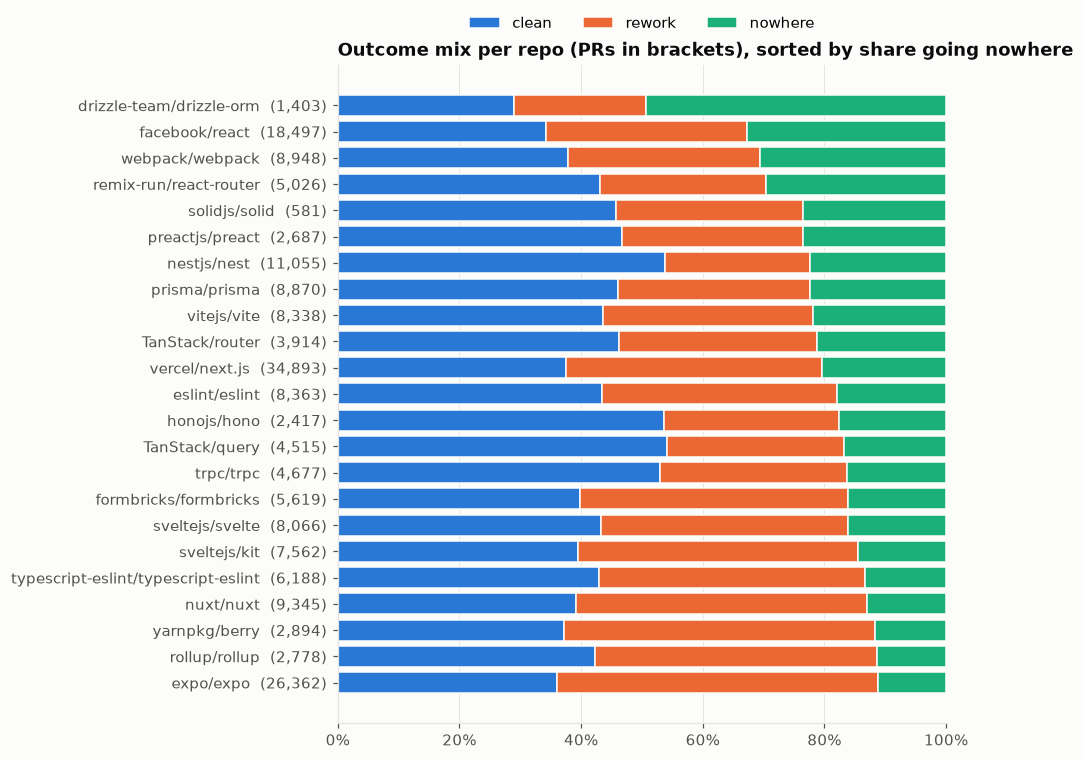

goes_nowhere share ranges from 11% to 49%


In [3]:
y = d["outcome_3class"]
mix = y.value_counts(dropna=False)
display(pd.DataFrame({"PRs": mix, "share": (mix / mix.sum()).round(3)}))

per_repo = pd.crosstab(d["repo"], y, normalize="index")[CLASSES]
per_repo = per_repo.loc[per_repo["goes_nowhere"].sort_values().index]
n_repo = d["repo"].value_counts()
fig, ax = plt.subplots(figsize=(9, 7))
left = np.zeros(len(per_repo))
for c in CLASSES:
    ax.barh(range(len(per_repo)), per_repo[c], left=left, color=COL[c], label=SHORT[c], height=0.8,
            edgecolor=SURFACE, linewidth=1)
    left += per_repo[c].to_numpy()
ax.set_yticks(range(len(per_repo)), [f"{r}  ({n_repo[r]:,})" for r in per_repo.index])
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_title("Outcome mix per repo (PRs in brackets), sorted by share going nowhere")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.show()
print("goes_nowhere share ranges from", f"{per_repo['goes_nowhere'].min():.0%} to {per_repo['goes_nowhere'].max():.0%}")

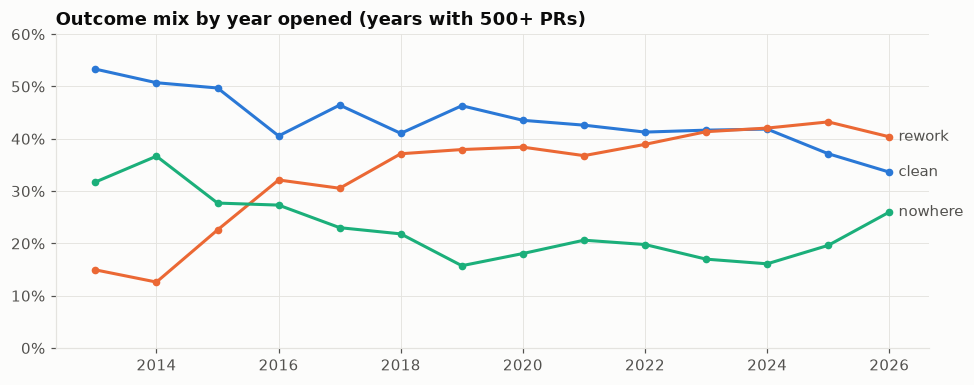

In [4]:
yr = d.assign(year=d["created"].dt.year)
by_year = pd.crosstab(yr["year"], yr["outcome_3class"], normalize="index")[CLASSES]
counts = yr["year"].value_counts().sort_index()
by_year = by_year[counts.reindex(by_year.index) >= 500]
fig, ax = plt.subplots(figsize=(9, 3.6))
for c in CLASSES:
    ax.plot(by_year.index, by_year[c], color=COL[c], marker="o", markersize=4)
    ax.annotate(SHORT[c], (by_year.index[-1], by_year[c].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK2)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.set_ylim(0, 0.6)
ax.set_title("Outcome mix by year opened (years with 500+ PRs)")
plt.tight_layout(); plt.show()

The three outcomes are close to balanced overall (41% clean, 39% rework, 20% nowhere), but **repos differ a lot**:
the share going nowhere ranges several-fold across repos. A model that meets a new repo has to cope with that spread,
which is the main reason scores drop on repos it has not seen. The mix also **drifts over time**: clean PRs fell from
about half in 2013 to about a third in 2026, and goes-nowhere rose from 16% in 2024 to 26% in 2026. Part of the 2026 rise may be
selection (only PRs that have closed are in the data), but a model trained on older years will under-predict recent nowhere.

## 3. Who opens the PRs

In [5]:
bot = d["author_is_bot"].fillna(False).astype(bool)
maint = d["author_confirmed_maintainer"].fillna(False).astype(bool)
merged_before = pd.to_numeric(d["author_prs_merged_repo"], errors="coerce").fillna(0) > 0
d["contributor_type"] = np.select([bot, maint, merged_before], ["bot", "maintainer", "returning"], "first_time")
t = pd.crosstab(d["contributor_type"], y)[CLASSES]
t["PRs"] = t.sum(axis=1)
display((t[CLASSES].div(t["PRs"], axis=0)).round(3).assign(PRs=t["PRs"]).sort_values("PRs", ascending=False))
display(pd.crosstab(d["ai_agent_authored"].astype(str), y, normalize="index")[CLASSES].round(3)
        .assign(PRs=d["ai_agent_authored"].astype(str).value_counts()))

outcome_3class,lands_clean,lands_after_rework,goes_nowhere,PRs
contributor_type,,,,
maintainer,0.452,0.467,0.081,93508
first_time,0.305,0.260,0.435,43082
returning,0.368,0.457,0.174,28788
bot,0.473,0.276,0.251,27585


outcome_3class,lands_clean,lands_after_rework,goes_nowhere,PRs
ai_agent_authored,,,,
False,0.410,0.392,0.198,191862
True,0.263,0.489,0.248,1136


`contributor_type` is built **only from what was known at open**: the bot flag, whether the author had already merged or
closed someone else's PR (`author_confirmed_maintainer`), and whether they had a PR merged in the repo before
(`author_prs_merged_repo`). First-time authors go nowhere far more often than maintainers. AI-agent PRs are rare (under 1%).

## 4. Leaks: columns that know the future

A leak is a column that carries information from after the PR opened. It makes offline scores look better than production.

In [6]:
first = d[(pd.to_numeric(d["author_prs_merged_repo"], errors="coerce") == 0) & ~maint & ~bot]
leak = pd.crosstab(first["author_association"], first["outcome_3class"], normalize="index")[CLASSES].round(3)
leak["PRs"] = first["author_association"].value_counts()
print("Authors with nothing merged before and no maintainer history (so all first-timers when they opened the PR):")
display(leak)

Authors with nothing merged before and no maintainer history (so all first-timers when they opened the PR):


outcome_3class,lands_clean,lands_after_rework,goes_nowhere,PRs
author_association,,,,
COLLABORATOR,0.326,0.326,0.348,92
CONTRIBUTOR,0.420,0.395,0.185,24321
MEMBER,0.307,0.405,0.288,726
NONE,0.048,0.033,0.920,15228


**`author_association` leaks the outcome.** It is GitHub's *current* status, read when the data was mined. Among authors who
were all first-timers at open, those now marked `NONE` went nowhere 92% of the time and those now marked `CONTRIBUTOR` 20%:
the label records whether something of theirs merged *later*. `FIRST_TIME_CONTRIBUTOR` never appears. It must not be a feature.

In [7]:
cols = ["author_prs_merged_repo", "AGE", "max_file_post_merge_ci_fail_rate", "ccn_delta", "n_funcs_modified"]
blank = d[cols].isna().groupby(y).mean()[cols].T[CLASSES]
blank.columns = [f"blank when {SHORT[c]}" for c in CLASSES]
display(blank.round(3))
print("observed_through blank, by outcome:")
display(d["observed_through"].isna().groupby(y).mean().round(3).to_frame("blank share").T)

,blank when clean,blank when rework,blank when nowhere
author_prs_merged_repo,0.039,0.017,0.000
AGE,0.011,0.018,0.034
max_file_post_merge_ci_fail_rate,0.891,0.859,0.846
ccn_delta,0.003,0.007,0.007
n_funcs_modified,0.003,0.007,0.007


observed_through blank, by outcome:


outcome_3class,goes_nowhere,lands_after_rework,lands_clean
blank share,1.0,0.0,0.0


In [8]:
skip = {"repo", "pr_number", "head_sha", "base_sha", "author_email", "created_at", "closed_at", "merged_at", "mined_at",
        "observed_through", "outcome_3class", "nowhere_reason", "close_reason", "close_reason_source", "merge_via",
        "open_snapshot", "miner_version", "miner_commit", "llm_model", "llm_prompt_version", "domain", "post_open_commits",
        "post_open_force_pushes", "changes_requested_reviews", "ci_observed", "ci_fail_flaky_only", "label_bad_observed",
        "revert_window_closed", "hotfix_window_closed", "szz_window_closed", "created", "closed", "contributor_type"}
rows = []
for c in d.columns:
    if c in skip or c.startswith(("label_", "days_to_")):
        continue
    b = d[c].isna().groupby(y).mean()
    if b.max() >= 0.005:
        rows.append({"column": c, **{f"blank when {SHORT[k]}": b[k] for k in CLASSES},
                     "ratio max/min": (b.max() + 1e-3) / (b.min() + 1e-3)})
blanks = pd.DataFrame(rows).sort_values("ratio max/min", ascending=False)
print("Every feature: how often it is blank, per outcome (largest differences first)")
display(blanks.head(12).round(3).reset_index(drop=True))

Every feature: how often it is blank, per outcome (largest differences first)


,column,blank when clean,blank when rework,blank when nowhere,ratio max/min
0,base_behind_by,0.000,0.096,0.041,83.606
1,author_prs_merged_repo,0.039,0.017,0.000,40.082
2,LT,0.001,0.005,0.007,3.422
3,la_norm,0.001,0.005,0.007,3.422
4,ld_norm,0.001,0.005,0.007,3.422
5,sum_hotfix_count_365d,0.001,0.005,0.007,3.422
6,author_days_since_last_change,0.183,0.156,0.496,3.170
7,AGE,0.011,0.018,0.034,3.031
8,head_from_fork,0.078,0.063,0.164,2.556
9,max_ccn_changed_func,0.003,0.007,0.007,2.301


In [9]:
os_tab = pd.crosstab(d["open_snapshot"], y, normalize="columns")[CLASSES]
os_tab.columns = [SHORT[c] for c in CLASSES]
print("How the at-open diff was found (open_snapshot), share of each outcome:")
display(os_tab.round(3))
print("base_behind_by is blank exactly on 'final' rows:",
      bool((d["base_behind_by"].isna() == (d["open_snapshot"] == "final")).all()))

How the at-open diff was found (open_snapshot), share of each outcome:


,clean,rework,nowhere
open_snapshot,,,
approx,0.011,0.008,0.000
exact,0.988,0.521,0.832
final,0.000,0.096,0.041
recovered,0.000,0.375,0.126


base_behind_by is blank exactly on 'final' rows: True


**The at-open diff's recovery method tracks the outcome.** The miner rebuilds each PR's diff as it was at open. When the head
has not moved since (`exact`) that is trivial; when later pushes replaced it, the diff is `recovered` from history or, failing
that, only the `final` diff exists. A PR that landed clean was never pushed to, so its diff is always exact; rework PRs were pushed
to, so 47% of them are recovered or final. `open_snapshot` is not a feature, but its fingerprints are:

- `base_behind_by` is blank exactly on `final` rows (0% of clean PRs, 9.6% of rework), and the loader blanks 125 diff features on
  `final` rows, so "blank diff" means "not clean";
- a `recovered` diff may differ in small, systematic ways from an exact one.

At real scoring time the webhook fires at open, so the diff is always exact: these rows teach a pattern production never shows.
`final` rows should be dropped (Nishit's script does), and whether `recovered` rows carry a detectable fingerprint should be tested
before training on them (question below).

**Blanks can leak too.** `author_prs_merged_repo` is blank only on PRs that later merged (never on goes-nowhere PRs), so
"blank" means "merged". `AGE`'s blanks lean the other way. `head_from_fork` is blank when the fork was **deleted later**
(16% of goes-nowhere PRs against 7% of clean ones), which is future information; a deleted head repo was a fork, so blank should read
as "fork". `author_days_since_last_change` is blank when the author never changed the repo before, which is known at open and
fine. These blanks need filling (or the column recomputing) so the model
cannot read the outcome from the gap.

`observed_through` is blank on **every** goes-nowhere PR (it is the post-merge observation cut-off). Any "drop PRs too recent to
have settled" filter built on it silently drops every goes-nowhere PR; the repo's data cut-off has to stand in.

Other columns that are not as of open, from the miner's own documentation: the **body** columns (`body_len`, `has_linked_issue`,
`body_*`, `agent_boilerplate`) are read at mining time, so they can see later edits; `post_open_*` and
`changes_requested_reviews` are counts after open (they define rework). `title_len` and `has_milestone` are rebuilt as of open
and are safe.

## 5. Missing values

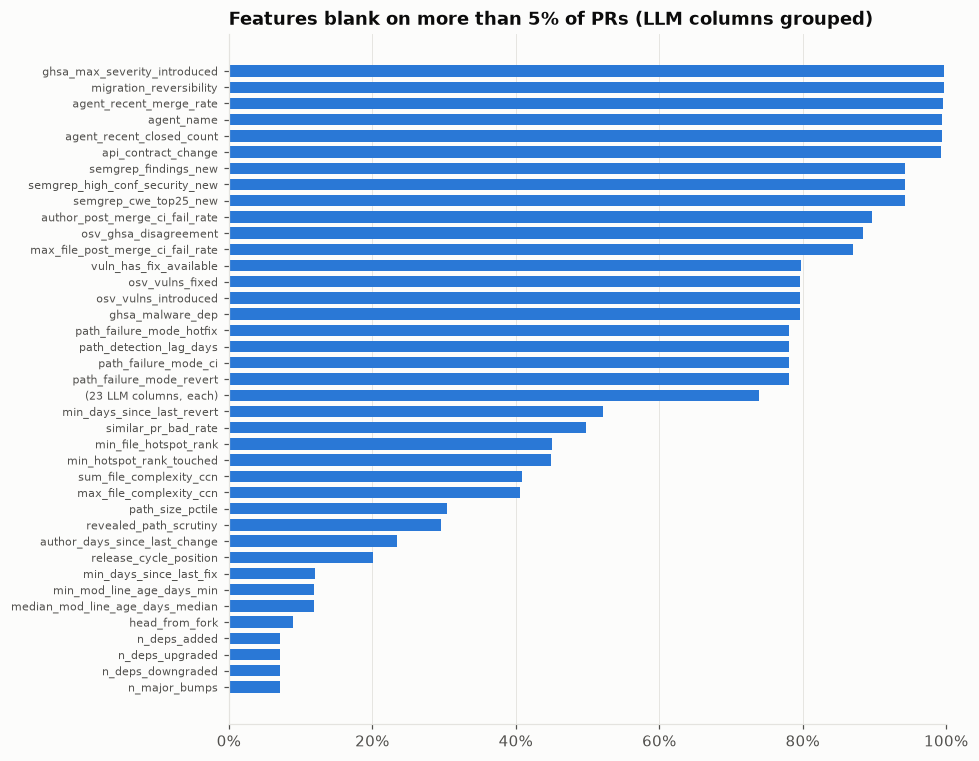

LLM columns are filled for 26% of PRs (only the miner's LLM scope: outside, non-bot PRs plus a 5% sample).


In [10]:
LLM = ["llm_touches_authn_authz", "authz_check_change", "changes_public_api_signature", "error_handling_change",
       "exception_swallowed", "db_schema_or_query_change", "transaction_boundary_change", "input_validation_change",
       "config_or_feature_flag_change", "feature_flag_guarding", "security_sensitive_ops", "resource_lifecycle_change",
       "null_handling_change", "numeric_money_precision", "time_handling_change", "retry_timeout_idempotency_change",
       "refactor_vs_behavior", "change_intent", "unrelated_change_share", "tests_added_for_behavior_change",
       "test_code_alignment", "satd_added", "semantic_risk_1to5"]
feat_cols = [c for c in d.columns if c not in skip and not c.startswith(("label_", "days_to_")) and c not in LLM
             and c != "llm_diff_truncated"]
miss = d[feat_cols].isna().mean()
miss["(23 LLM columns, each)"] = d[LLM].isna().mean().mean()
miss = miss[miss > 0.05].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, max(3, 0.18 * len(miss))))
ax.barh(range(len(miss)), miss.values, color="#2a78d6", height=0.7)
ax.set_yticks(range(len(miss)), miss.index, fontsize=7); ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_title(f"Features blank on more than 5% of PRs (LLM columns grouped)")
plt.tight_layout(); plt.show()
llm = ["semantic_risk_1to5", "change_intent", "refactor_vs_behavior", "test_code_alignment"]
print("LLM columns are filled for", f"{d[llm[0]].notna().mean():.0%}", "of PRs (only the miner's LLM scope: outside, non-bot PRs plus a 5% sample).")

Most heavy blanks are by design: the 23 LLM columns exist only for PRs in the miner's LLM scope (about 26%), CI- and
breakage-history columns need history the repo may not have, agent columns exist only for agent PRs. A blank is "unknown",
not zero, and tree models can use it as such, except where the blank itself tracks the outcome (section 4).

## 6. The other labels

In [11]:
nw = d[y == "goes_nowhere"]
display(nw["nowhere_reason"].value_counts(dropna=False).rename("PRs").to_frame()
        .assign(share=lambda t: (t["PRs"] / t["PRs"].sum()).round(3)).T)
m = d[y != "goes_nowhere"]
rows = []
for lab, obs in [("label_bad", "label_bad_observed"), ("label_revert", "revert_window_closed"),
                 ("label_hotfix", "hotfix_window_closed"), ("label_szz_bug", "szz_window_closed"),
                 ("label_ci_fail", "ci_observed")]:
    fired = (m[lab] == True).to_numpy()                                     # noqa: E712
    known = (m[obs] == True).to_numpy() | fired                             # noqa: E712  observed, or it fired
    rows.append(dict(label=lab, observed_by=obs, merged_PRs=len(m), label_known=int(known.sum()),
                     known_share=round(known.mean(), 3), positives=int(fired.sum()),
                     positive_rate_when_known=round(fired[known].mean(), 4)))
display(pd.DataFrame(rows))

nowhere_reason,abandoned,unknown,duplicate,unwanted,ci_technical,NaN
PRs,12954.000,10044.000,7132.000,5201.000,2931.000,4.0
share,0.339,0.262,0.186,0.136,0.077,0.0


,label,observed_by,merged_PRs,label_known,known_share,positives,positive_rate_when_known
0,label_bad,label_bad_observed,154732,19926,0.129,5457,0.274
1,label_revert,revert_window_closed,154732,154732,1.000,1057,0.007
2,label_hotfix,hotfix_window_closed,154732,154732,1.000,277,0.002
3,label_szz_bug,szz_window_closed,154732,145767,0.942,33466,0.230
4,label_ci_fail,ci_observed,154732,18773,0.121,4174,0.222


Why a PR goes nowhere splits fairly evenly between abandoned, unwanted, duplicate and unknown, with CI problems rare.
The **breakage labels are thin or noisy**: the miner's `label_bad` (revert, hotfix or a CI failure after merge) is observed on
only 13% of merged PRs, because GitHub keeps CI results about 90 days, and is positive on 27% of those. Reverts (0.7%) and hotfixes
(0.2%) are observed everywhere but rare. `label_szz_bug` (a later bug fix traced back to this change) is positive on 23%: plentiful
but a loose proxy. Note that Nishit's script redefines `label_bad` as revert OR hotfix (ADR 0021), which is far rarer than the
miner's version; the output must say which one it predicts. A blank label means "not observed", never "no".

## 7. Which features carry signal on their own

AUROC of each feature alone, for each outcome against the rest (0.5 = no signal, 1 = perfect; a value below 0.5 means the
feature works in reverse, so the table shows the stronger direction). Computed on at-open features only.

In [12]:
def auroc(pos, x):
    ok = np.isfinite(x)
    pos, x = pos[ok], x[ok]
    n1, n0 = pos.sum(), (~pos).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(x).rank().to_numpy()
    return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


NOT_FEATURES = {"repo", "pr_number", "head_sha", "base_sha", "author_email", "created_at", "closed_at", "merged_at",
                "mined_at", "observed_through", "outcome_3class", "nowhere_reason", "close_reason", "close_reason_source",
                "merge_via", "open_snapshot", "miner_version", "miner_commit", "llm_model", "llm_prompt_version",
                "domain", "author_association", "post_open_commits", "post_open_force_pushes",
                "changes_requested_reviews", "ci_observed", "ci_fail_flaky_only", "llm_diff_truncated", "label_bad_observed",
                "revert_window_closed", "hotfix_window_closed", "szz_window_closed", "created", "closed", "contributor_type"}
BODY = {"body_len", "has_linked_issue", "body_headings", "body_checklist_items", "body_has_test_plan", "agent_boilerplate"}
num = {}
for c in d.columns:
    if c in NOT_FEATURES or c in BODY or c.startswith(("label_", "days_to_")):
        continue
    s = d[c]
    if s.dtype == bool or s.dtype == object and set(s.dropna().unique()) <= {True, False}:
        num[c] = s.map({True: 1.0, False: 0.0}).astype(float).to_numpy()
    elif pd.api.types.is_numeric_dtype(s):
        num[c] = s.astype(float).to_numpy()
X = pd.DataFrame(num)
known = y.isin(CLASSES).to_numpy()
recs = []
for c in X.columns:
    x = X[c].to_numpy()[known]
    if np.isfinite(x).sum() < 1000 or np.nanstd(x) == 0:
        continue
    r = {"feature": c, "filled": np.isfinite(x).mean()}
    for k in CLASSES:
        a = auroc((y[known] == k).to_numpy(), x)
        r[SHORT[k]] = max(a, 1 - a)
    recs.append(r)
uni = pd.DataFrame(recs)
uni["best"] = uni[["clean", "rework", "nowhere"]].max(axis=1)
uni = uni.sort_values("best", ascending=False).reset_index(drop=True)
print(f"{len(uni)} at-open numeric features; strongest 25:")
display(uni.head(25).round(3))

138 at-open numeric features; strongest 25:


,feature,filled,clean,rework,nowhere,best
0,author_prs_merged_repo,0.977,0.600,0.570,0.753,0.753
1,agent_recent_closed_count,0.006,0.567,0.607,0.715,0.715
2,SEXP,1.000,0.563,0.573,0.705,0.705
3,REXP,1.000,0.575,0.556,0.699,0.699
4,EXP,1.000,0.571,0.557,0.694,0.694
5,author_confirmed_maintainer,1.000,0.542,0.576,0.677,0.677
6,LA,1.000,0.668,0.675,0.507,0.675
7,author_file_familiarity,1.000,0.591,0.522,0.671,0.671
8,pr_size_pctile_repo,1.000,0.650,0.659,0.511,0.659
9,author_account_age_days,1.000,0.506,0.599,0.656,0.656


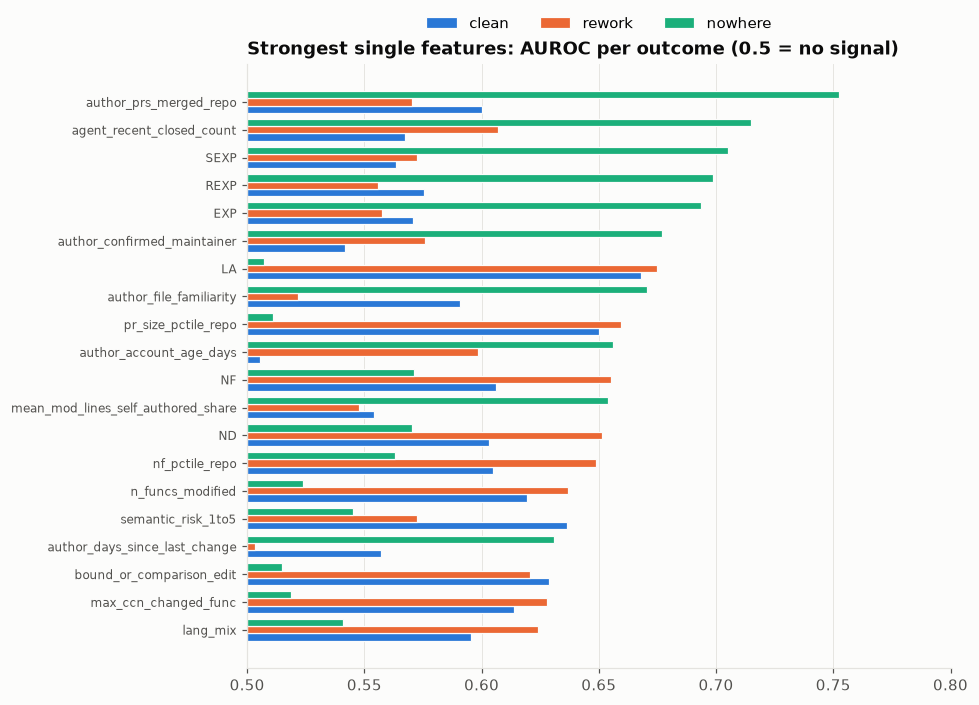

In [13]:
top = uni.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
h = 0.26
for i, k in enumerate(["clean", "rework", "nowhere"]):
    cls = [c for c in CLASSES if SHORT[c] == k][0]
    ax.barh(np.arange(len(top)) + (i - 1) * h, top[k] - 0.5, left=0.5, height=h, color=COL[cls], label=k,
            edgecolor=SURFACE, linewidth=0.8)
ax.set_yticks(range(len(top)), top["feature"], fontsize=8)
ax.set_xlim(0.5, max(0.8, top[["clean", "rework", "nowhere"]].max().max() + 0.02))
ax.grid(axis="y", visible=False)
ax.set_title("Strongest single features: AUROC per outcome (0.5 = no signal)")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.show()

No single at-open feature comes near 0.85 (the eval's "suspiciously good" line), so nothing obvious leaks. The strongest
signals are **who the author is** (earlier merged PRs, `EXP`/`REXP`/`SEXP` experience, file familiarity, account age, maintainer
status), which mostly separates goes-nowhere, and **PR size** (`LA`, `NF`, `ND`, size percentiles, functions changed), which
mostly separates clean from rework. `agent_recent_closed_count` ranks second but is filled on only 0.6% of PRs (agent PRs). Each
feature alone is weak; the model's job is to combine them.

## 8. Correlation between features

Spearman rank correlation between the 30 strongest features (rank-based, so skewed counts and yes/no columns are handled).
Ordered so that correlated features sit together. Blue = move together, red = move oppositely, grey = unrelated.

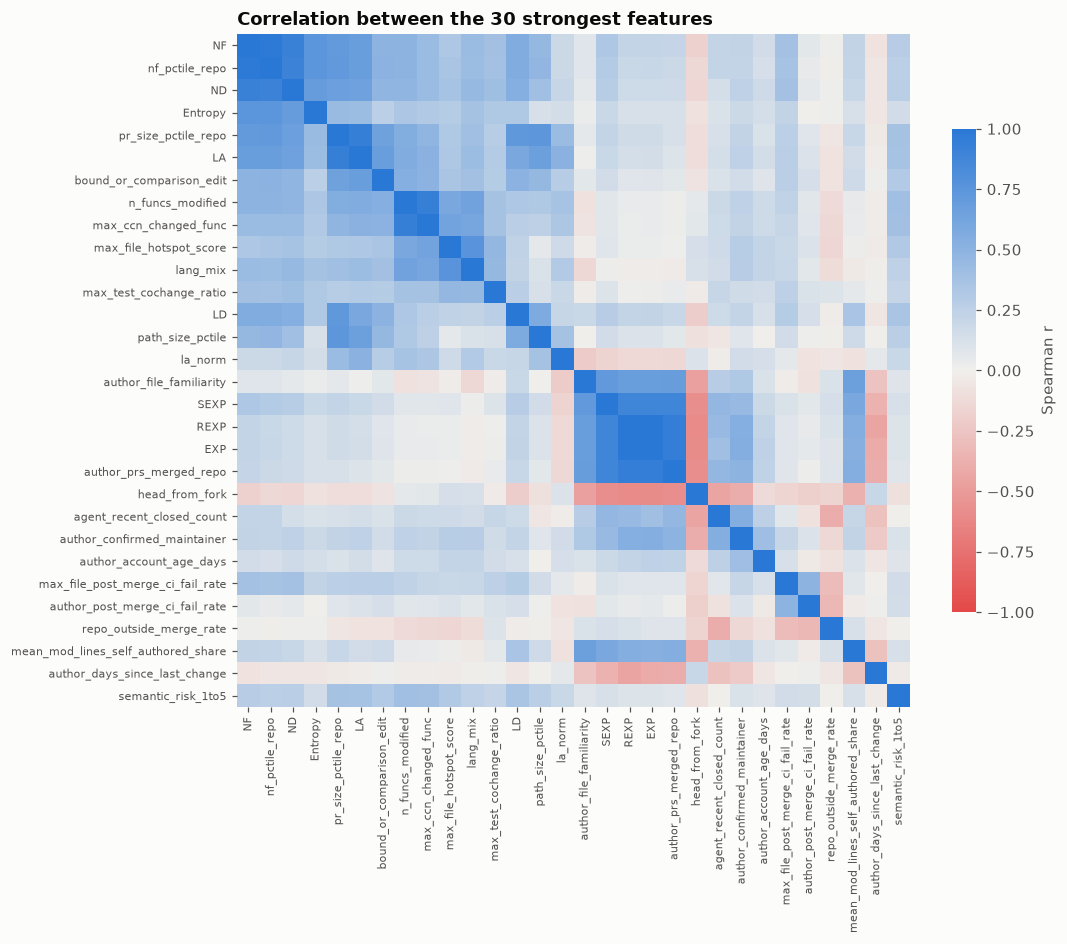

Most correlated pairs (|r| > 0.8):


r
REXP                EXP                     0.992
NF                  nf_pctile_repo          0.980
EXP                 author_prs_merged_repo  0.941
REXP                author_prs_merged_repo  0.938
pr_size_pctile_repo LA                      0.930
n_funcs_modified    max_ccn_changed_func    0.930
NF                  ND                      0.922
nf_pctile_repo      ND                      0.900
SEXP                REXP                    0.888
                    author_prs_merged_repo  0.886
                    EXP                     0.885

In [14]:
top30 = uni.head(30)["feature"].tolist()
corr = X.loc[known, top30].rank().corr()
# order by hierarchical clustering on 1 - |r| (simple greedy chain, no scipy needed)
dist = 1 - corr.abs().to_numpy()
order, left = [int(np.argmin(dist.sum(axis=1)))], set(range(len(top30)))
left.discard(order[0])
while left:
    nxt = min(left, key=lambda j: dist[order[-1], j])
    order.append(nxt); left.discard(nxt)
corr = corr.iloc[order, order]
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.to_numpy(), cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), corr.index, fontsize=7)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7); cb.outline.set_visible(False); cb.set_label("Spearman r", color=INK2)
ax.set_title("Correlation between the 30 strongest features")
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("Most correlated pairs (|r| > 0.8):")
display(pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(3).to_frame("r"))

Two blocks dominate: **author experience** (`EXP`, `REXP`, `SEXP`, `author_file_familiarity`, `author_prs_merged_repo`,
maintainer status) and **PR size** (`LA`, `LD`, `NF`, `ND`, size percentiles). Features within a block largely say the same thing.
That is harmless for tree models but means the signal is narrower than the feature count suggests, and it is a hint for
feature engineering: ratios and per-repo normalisations (size relative to the repo's usual PR) add more than another raw count.

## 9. PR size, time to close and repo differences

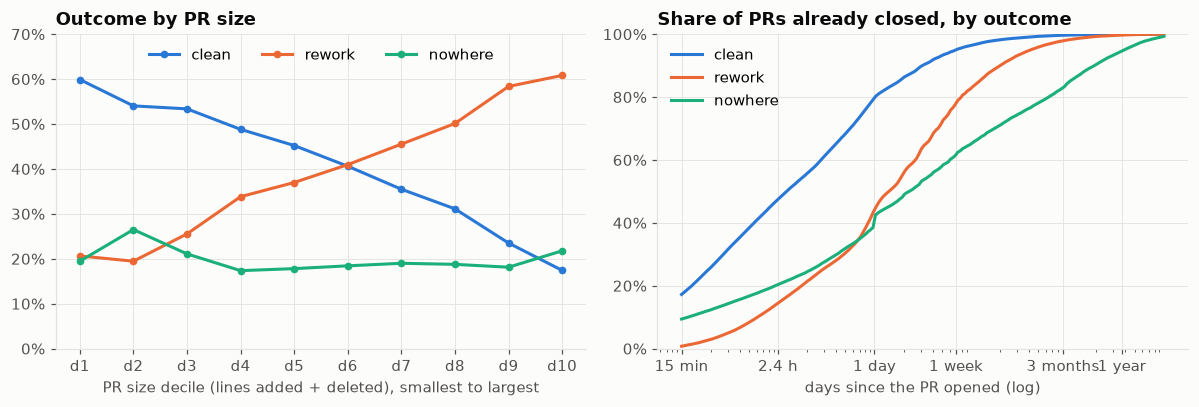

outcome_3class,goes_nowhere,lands_after_rework,lands_clean
median days open,2.3,1.4,0.1


In [15]:
size = pd.to_numeric(d["LA"], errors="coerce") + pd.to_numeric(d["LD"], errors="coerce")
q = pd.qcut(size.rank(method="first"), 10, labels=[f"{i}0%" for i in range(1, 11)])
by_size = pd.crosstab(q, y, normalize="index")[CLASSES]
days = (d["closed"] - d["created"]).dt.total_seconds() / 86400
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for c in CLASSES:
    axes[0].plot(range(10), by_size[c], color=COL[c], marker="o", markersize=4, label=SHORT[c])
axes[0].set_xticks(range(10), [f"d{i}" for i in range(1, 11)])
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); axes[0].set_ylim(0, 0.7)
axes[0].set_xlabel("PR size decile (lines added + deleted), smallest to largest")
axes[0].set_title("Outcome by PR size"); axes[0].legend(ncol=3, loc="upper center")
grid_days = np.logspace(-2, 3, 200)
for c in CLASSES:
    v = np.sort(days[y == c].dropna().to_numpy())
    axes[1].plot(grid_days, np.searchsorted(v, grid_days, side="right") / len(v), color=COL[c], label=SHORT[c])
axes[1].set_xscale("log"); axes[1].set_xlabel("days since the PR opened (log)")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); axes[1].set_ylim(0, 1)
axes[1].set_xticks([0.01, 0.1, 1, 7, 90, 365], ["15 min", "2.4 h", "1 day", "1 week", "3 months", "1 year"])
axes[1].set_title("Share of PRs already closed, by outcome"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()
display(days.groupby(y).median().round(1).rename("median days open").to_frame().T)

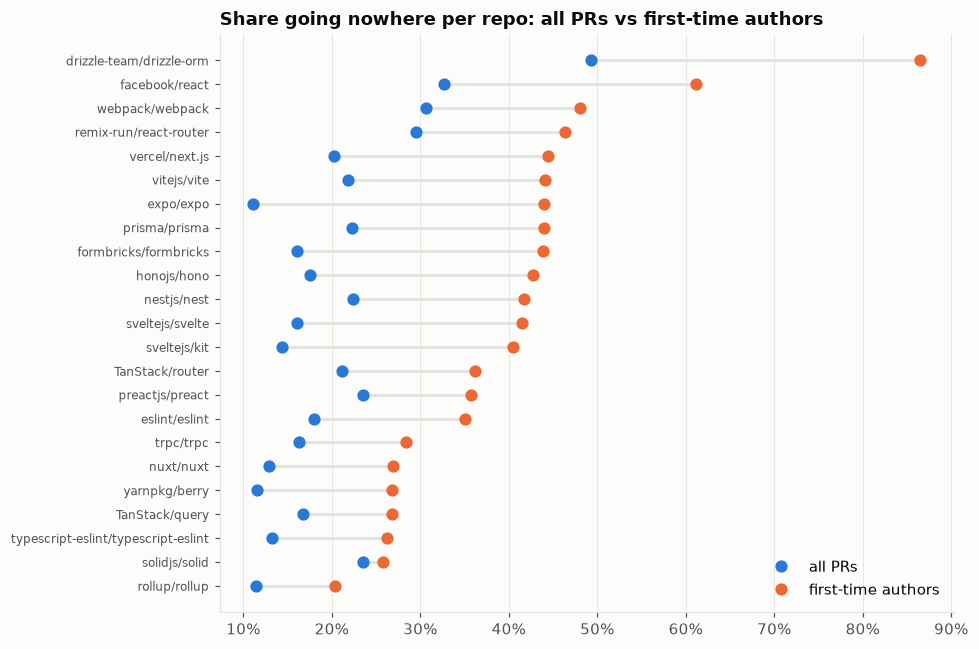

In [16]:
ft = d[d["contributor_type"] == "first_time"]
rates = pd.DataFrame({"first-time authors": (ft["outcome_3class"] == "goes_nowhere").groupby(ft["repo"]).mean(),
                      "all PRs": (y == "goes_nowhere").groupby(d["repo"]).mean()}).sort_values("first-time authors")
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(rates))
ax.hlines(yy, rates["all PRs"], rates["first-time authors"], color=GRID, linewidth=2)
ax.plot(rates["all PRs"], yy, "o", color="#2a78d6", markersize=7, label="all PRs")
ax.plot(rates["first-time authors"], yy, "o", color="#eb6834", markersize=7, label="first-time authors")
ax.set_yticks(yy, rates.index, fontsize=8); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Share going nowhere per repo: all PRs vs first-time authors")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Size decides clean against rework**: 60% of the smallest PRs land clean against 17% of the largest, and rework rises
from 20% to 61%. Goes-nowhere barely depends on size (17% to 27%). Clean PRs close fastest (half within 2.4 hours), and
goes-nowhere PRs linger longest, which is why "PR age" is a strong queue signal. The last chart is the core
difficulty: the **same kind of author meets very different odds in different repos** (first-time authors go nowhere a small
fraction of the time in some repos and most of the time in others). A model that knows the repo's recent history can adjust; one
meeting a brand-new repo cannot, except through history features built from that repo's earlier PRs.

## 10. Findings and questions

**What the data says**
1. 193k closed PRs from 23 web/TypeScript repos; outcomes roughly 41% clean, 39% rework, 20% nowhere, with large differences between repos and some drift over time.
2. Leaks to keep out: `author_association` (current status, strongly tied to the outcome), the body columns (mining time), post-open counts, the blank patterns of `author_prs_merged_repo`, `AGE` and `head_from_fork`, and the fingerprints of `open_snapshot`: `final` rows (blank diff features and `base_behind_by`) never occur for clean PRs and never occur in production.
3. `observed_through` is blank on every goes-nowhere PR; maturity filters must use the repo's cut-off instead.
4. The strongest at-open signals are author experience, PR size and the repo's treatment of outside PRs; no single feature is suspiciously strong.
5. Features cluster into an author-experience block and a size block; the rest are weaker and often blank (LLM columns about 74% blank).
6. Breakage labels are thin (hotfix 277 positives, revert 1,057) or loose (`label_szz_bug`), and `label_bad` is defined differently by the miner and by Nishit's script.
7. Outcomes drift: goes-nowhere rose to 26% of 2026 PRs, so time-aware validation matters as well as new-repo validation.

**Feature ideas this suggests (for the model notebook)**
- Point-in-time **author history** in the repo: earlier PRs by outcome, open PRs at the time, days since their last PR (author key: `author_email`).
- Point-in-time **repo history**: the outcome mix and time-to-close of PRs that closed before this one opened, recent and long-run, for outside PRs and for all PRs.
- **Relative size**: this PR's size against the repo's recent PRs (percentile), rather than raw lines.
- Contributor type from at-open columns only; open hour and weekday.

**Questions for you**
- Which split should lead: by PR (repos seen in training) or by repo (new repos)? The plan is both, with a final model for each.
- Should the model be trained on every PR, or on outside contributors only (the PRs the review queue and the eval focus on)?
- `recovered` rows: 37% of rework PRs have a diff rebuilt after later pushes. Proposal: test whether a model can tell recovered from exact diffs among rework PRs; if it can (a fingerprint), drop them, otherwise keep them. `final` rows are dropped either way.
- `label_bad`: predict the miner's definition (includes CI failures, observed on 13%) or Nishit's (revert OR hotfix)?
- Anything here that looks wrong, or that you want explored further before modelling?